# FlightScope — classificação de atrasos aéreos

Case independente de Lucas Menghi com registros oficiais do BTS. CRISP-DM: estimar risco de partida ≥15 minutos atrasada para apoiar triagem operacional. Não é um serviço atual de status de voo.

In [1]:
from pathlib import Path
import json,pandas as pd
ROOT=Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
manifest=json.loads((ROOT/'reports/data_manifest.json').read_text())
pd.DataFrame(manifest['splits']).T

,n,start,end,delay_rate
calibration,15000,2025-09-01,2025-09-30,0.169067
policy,15000,2025-10-01,2025-10-31,0.191667
test,30000,2025-11-01,2025-12-31,0.232567
train,120000,2025-01-01,2025-08-31,0.223108


## Compreensão e preparação dos dados
12 arquivos mensais oficiais de 2025, SHA256 registrado. Voos domésticos reportados e operados, com DepDel15 observado e campos programados válidos. Amostra de 15.000 menores hashes por mês, sem estratificar pelo alvo. Cancelamentos excluídos; desvios mantidos quando a partida é observada. Os pesos de meses são iguais na amostra, não proporcionais ao tráfego nacional.

In [2]:
# Reproduzir download e preparação (~350 MB comprimidos)
# %run ../scripts/prepare.py
df=pd.read_json(ROOT/'data/processed/flights.jsonl',lines=True)
df.groupby('Month').agg(n=('label','size'),delay_rate=('label','mean'))

,n,delay_rate
Month,,
1,15000,0.182133
2,15000,0.195467
3,15000,0.196333
4,15000,0.184000
5,15000,0.226133
6,15000,0.283000
7,15000,0.287400
8,15000,0.230400
9,15000,0.169067


## Modelagem sem variáveis de desfecho
Somente companhia, origem/destino, horário programado, mês, dia da semana, distância e duração programada. Horário e mês têm codificação cíclica. Não usar partida/chegada reais, causas de atraso, taxiamento ou status de cancelamento como entrada. Quatro candidatos (duas regressões logísticas e dois LightGBM), duas janelas expansivas: jan–abr→mai–jun e jan–jun→jul–ago. Seleção por AP média.

In [3]:
development=pd.read_csv(ROOT/'reports/development.csv')
development.pivot(index='model',columns='train_end_month',values='average_precision')

train_end_month,4,6
model,,
lightgbm_15,0.377485,0.425718
lightgbm_31,0.366442,0.420875
logistic_c01,0.381877,0.406608
logistic_c1,0.376151,0.402473


## Calibração, limiar e congelamento
Modelo final treinado jan–ago. Setembro: calibração logística do logit dos scores. Outubro: limiar no percentil 80 dos scores calibrados. Novembro–dezembro: teste final, após congelar a configuração. A fila não terá necessariamente 20% em períodos futuros. Ranking top-20% é uma avaliação histórica separada, com capacidade fixa.

In [4]:
config=json.loads((ROOT/'reports/frozen_config.json').read_text())
config

{'seed': 42,
 'candidates': {'logistic_c01': {'kind': 'logistic', 'C': 0.1},
  'logistic_c1': {'kind': 'logistic', 'C': 1.0},
  'lightgbm_15': {'kind': 'lightgbm', 'leaves': 15, 'trees': 250},
  'lightgbm_31': {'kind': 'lightgbm', 'leaves': 31, 'trees': 400}},
 'selected': 'lightgbm_15',
 'selection': 'Mean average precision across two expanding temporal development windows',
 'train_months': [1, 8],
 'calibration_month': 9,
 'policy_month': 10,
 'test_months': [11, 12],
 'threshold_rule': '80th percentile of October calibrated scores, separately per model; fixed thereafter',
 'thresholds': {'selected': 0.25129464466697565,
  'logistic_baseline': 0.22951758577639475},
 'raw_inputs': ['Reporting_Airline',
  'Origin',
  'Dest',
  'CRSDepTime',
  'Month',
  'DayOfWeek',
  'Distance',
  'CRSElapsedTime'],
 'target': 'DepDel15 = 1, departure delay >=15 minutes'}

In [5]:
metrics=json.loads((ROOT/'reports/metrics.json').read_text())
pd.DataFrame({name:{k:v for k,v in metrics[name].items() if k!='confusion_matrix'} for name in ['selected','logistic_baseline']}).T

,average_precision,roc_auc,brier,precision,recall,queue_rate,threshold,precision_at20,recall_at20,lift_at20
selected,0.343485,0.655244,0.177944,0.415772,0.127705,0.071433,0.251295,0.370167,0.318332,1.591658
logistic_baseline,0.330312,0.644132,0.181099,0.369390,0.163967,0.103233,0.229518,0.354333,0.304715,1.523577


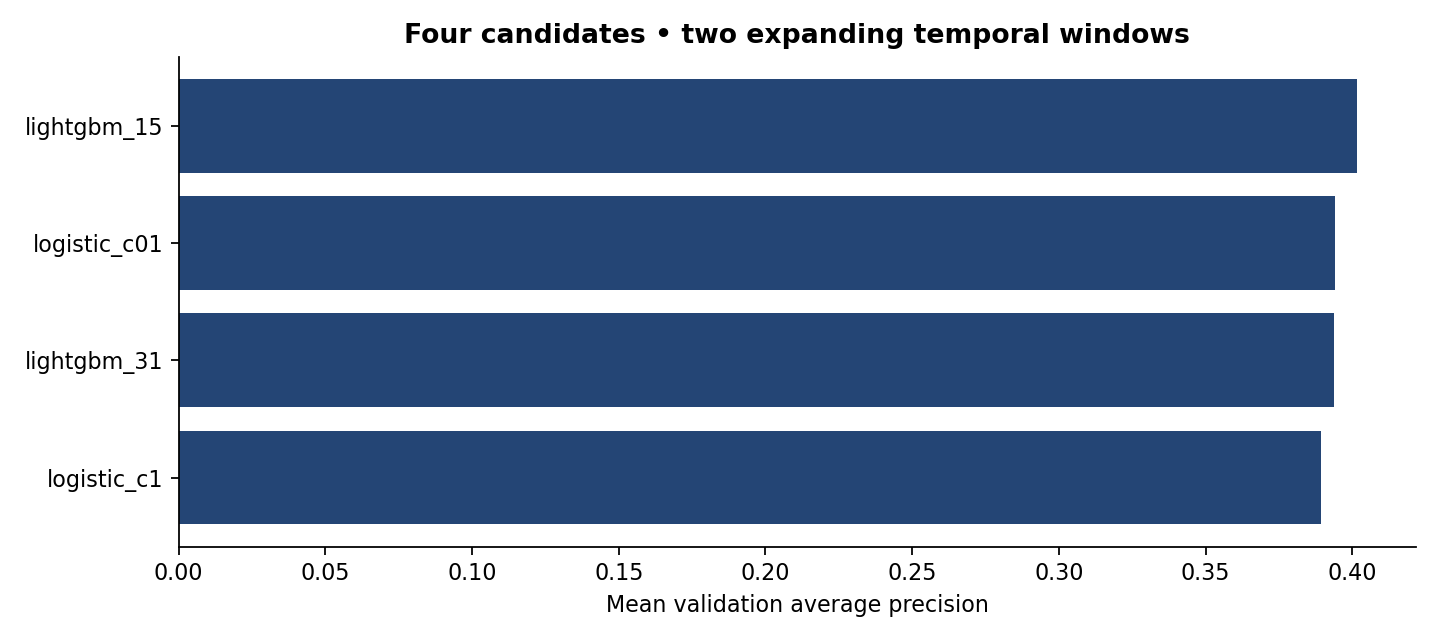

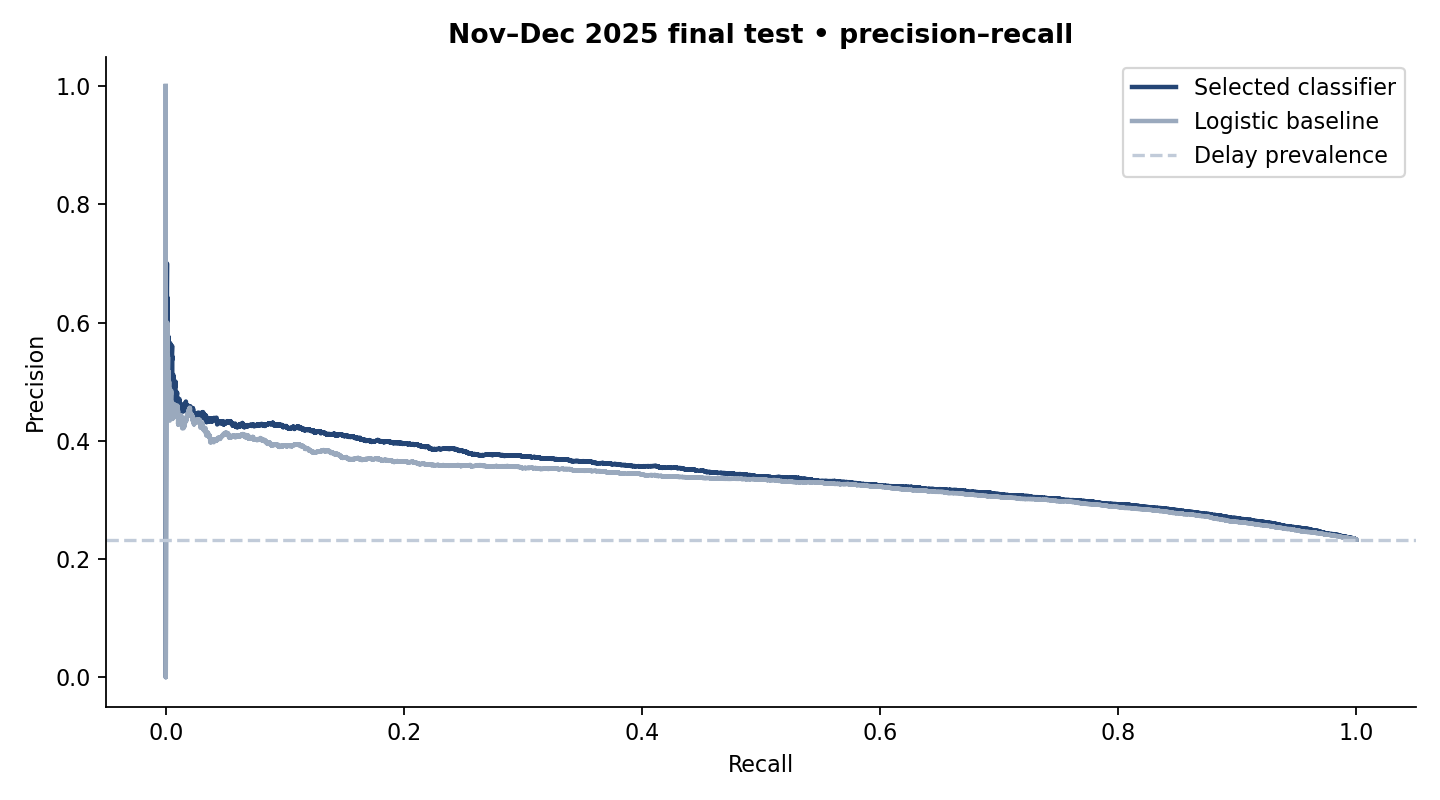

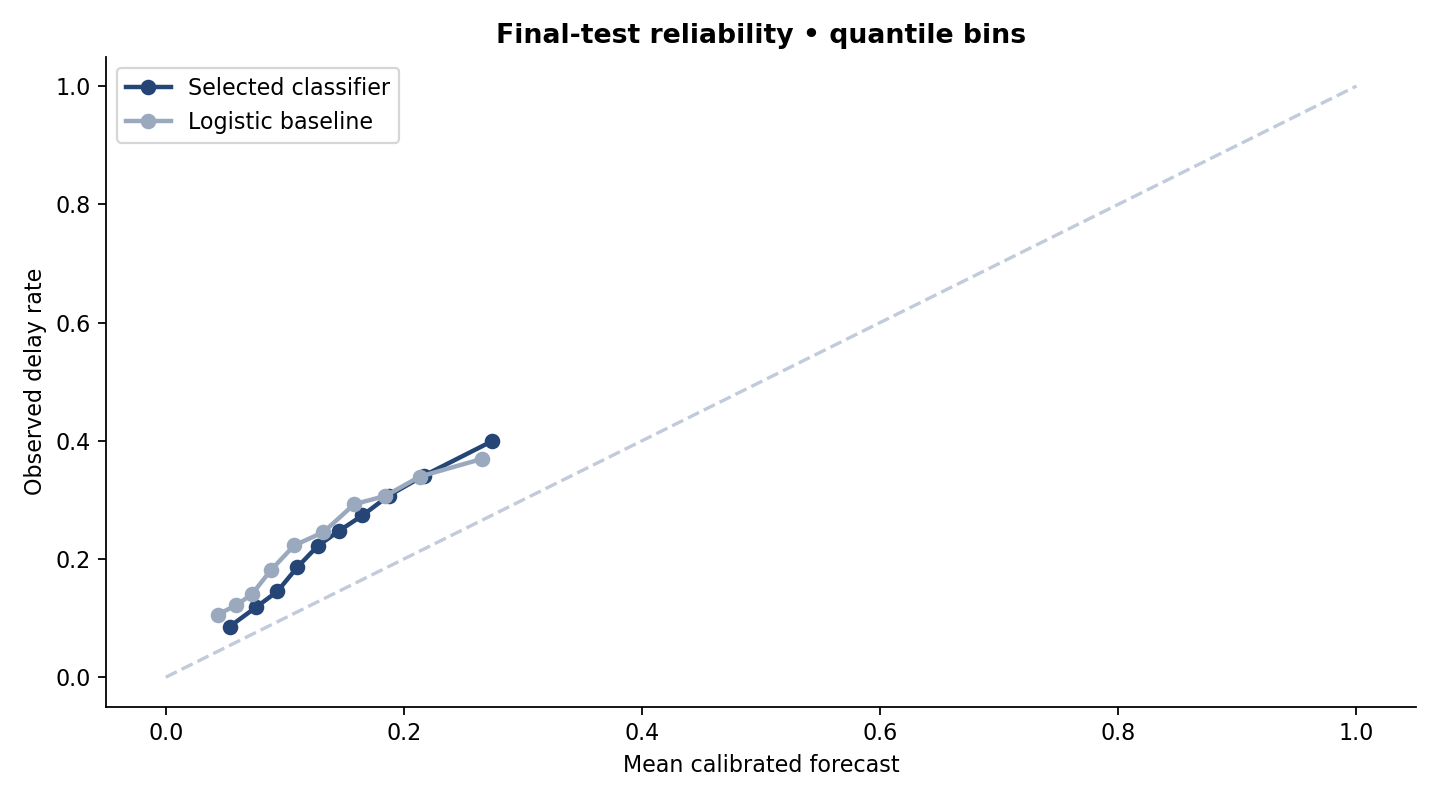

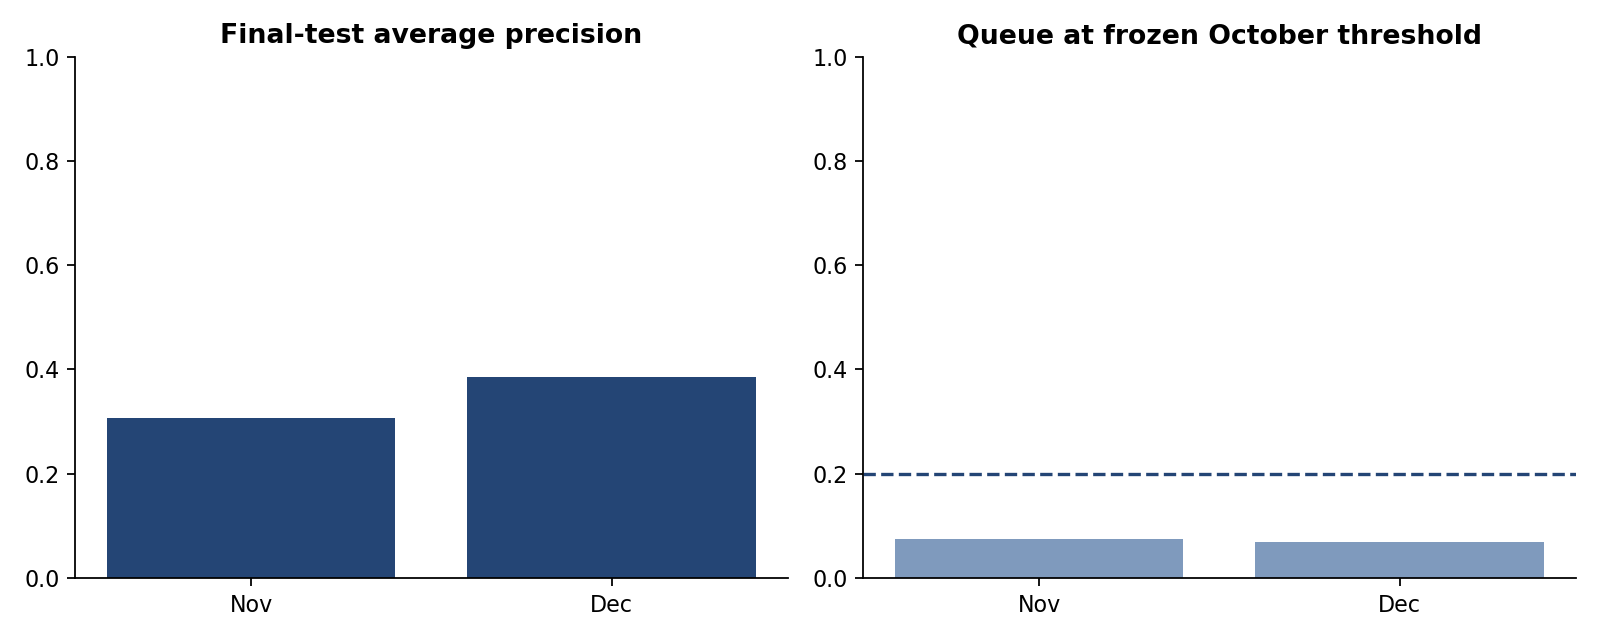

In [6]:
from IPython.display import Image,display
for name in ['development','precision_recall','calibration','monthly_stability']:
    display(Image(filename=str(ROOT/'reports/figures'/f'{name}.png')))

## Limites e aplicação
Dados históricos dos EUA, amostra com 15 mil voos por mês. Sem clima previsto, congestionamento em tempo real ou rotação da aeronave; não prevê cancelamentos. Campos programados no arquivo retrospectivo não são snapshots auditados do que era conhecido no momento da previsão. Bootstrap em blocos por dia considera correlação intradia, mas não entre dias. Não medir ROI ou redução de atrasos sem piloto. Reavaliar em outro ano/estação e validar a disponibilidade dos campos antes de operar.

In [7]:
scenarios=json.loads((ROOT/'reports/capacity_scenarios.json').read_text())
pd.DataFrame([{'capacity':s['capacity'],**s['selected']} for s in scenarios])

,capacity,queue,identified,precision,recall,lift
0,5,1500,640,0.426667,0.091730,1.834599
1,10,3000,1199,0.399667,0.171850,1.718504
2,15,4500,1723,0.382889,0.246954,1.646362
3,20,6000,2221,0.370167,0.318332,1.591658
4,25,7500,2692,0.358933,0.385839,1.543357
5,30,9000,3143,0.349222,0.450480,1.501600
6,35,10500,3548,0.337905,0.508528,1.452937
7,40,12000,3964,0.330333,0.568153,1.420381
8,45,13500,4348,0.322074,0.623190,1.384868
9,50,15000,4706,0.313733,0.674502,1.349004


## Fontes
- https://www.transtats.bts.gov/tables.asp?qo_vq=EFD
- https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ

Relatórios e figuras foram calculados pelos scripts executados. Cenários de capacidade são diagnósticos históricos e não escolhas adicionais do modelo.